# Project #1 - Dimensionality Reduction

### 1 Setup

#### Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

In [2]:
RANDOM_STATE = 42

# Configure NumPy.
rng = np.random.default_rng(seed=RANDOM_STATE)
np.set_printoptions(linewidth=100)

# Configure Seaborn.
sns.set_style("whitegrid")
sns.set_palette("deep")

#### Dataset

In [3]:
# https://drive.google.com/uc?id=1UZNOcb-bSL-aPPXWcPH4h4Kbx4G-bk9J
# !gdown 1UZNOcb-bSL-aPPXWcPH4h4Kbx4G-bk9J

In [4]:
mn_df = pd.read_csv("data/mnist_train.csv")

display(mn_df.sample(3, random_state=rng))

row_count, col_count = mn_df.shape
print(f"Dataset has {row_count:,} rows and {col_count} columns.")

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
27492,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3748,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
32505,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Dataset has 42,000 rows and 785 columns.


### 2 EDA

#### Feature vs Label

In [5]:
ftrs = mn_df.loc[[3]].drop(columns="label")
label = mn_df.loc[3, "label"].item()

row_str = ""
for row in ftrs.values.reshape((28, 28)):
    row_str += "".join(f"{col:>3}" for col in row) + "\n"
print(row_str)

  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0220179  6  0  0  0  0  0  0  0  0  9 77  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0 28247 17  0  0  0  0  0  0  0  0 27202  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0242155  0  0  0  0  0  0  0  0 27254 63  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0160207  6  0  0  0  0  0  0  0 27254 65  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0127254 21  0  0  0  0  0  0  0 20239 65  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0 77254 21  0  0  0  0  0  0  0  0195 65  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0 70254 21  0  0  0  0  0  0  0  0195142  0  

In [6]:
label

4

### 3 Training Setup

#### Train-Test split

In [7]:
X = mn_df.drop(columns="label")
y = mn_df["label"]

X.shape, y.shape

((42000, 784), (42000,))

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.76, random_state=RANDOM_STATE)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((10080, 784), (31920, 784), (10080,), (31920,))

#### Base Pipeline

In [9]:
base_pl = Pipeline(
    steps=[
        ("mm_scaling", MinMaxScaler()),
        ("pca", PCA(n_components=2)),
    ]
).set_output(transform="pandas")

In [10]:
pca = base_pl.named_steps["pca"]
pcs_df = base_pl.fit_transform(X_train)
tot_var = pca.explained_variance_ratio_.sum()

print("Shape after PCA:", pcs_df.shape)
print(f"Total variance captured by 2 PCs: {tot_var * 100:.2f}%")

pcs_df.sample(3, random_state=rng)

Shape after PCA: (10080, 2)
Total variance captured by 2 PCs: 16.83%


,pca0,pca1
493,-2.931164,-0.581900
26132,0.918827,-0.641664
20420,-2.586090,2.324749


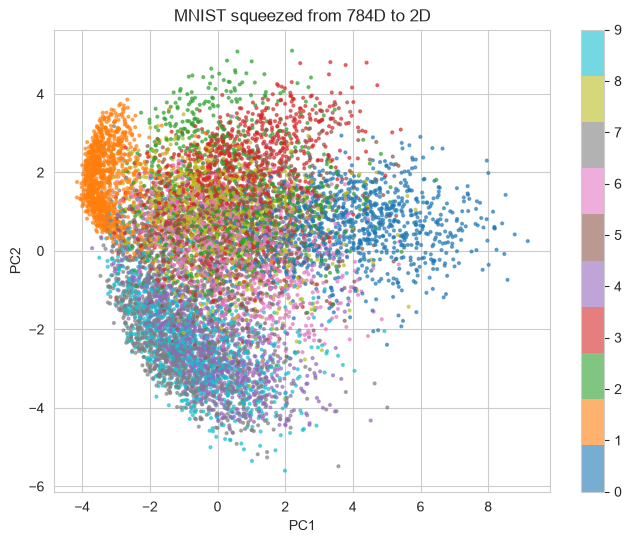

In [11]:
plt.figure(figsize=(8, 6))

sc = plt.scatter(data=pcs_df, x="pca0", y="pca1", c=y_train, cmap="tab10", s=4, alpha=0.6)
plt.colorbar(sc)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("MNIST squeezed from 784D to 2D")

plt.show()

#### PC vs Total variance

For calculating total variance captured by each new Principal Component, instead of taking all 784 dimensions which slows down below PCA, lets take fewer values towards higher dimensions.

In [12]:
n, d = X_train.shape

n_components_list = np.unique(np.geomspace(1, d, num=100, dtype=int))
n_components_list

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,  14,  15,  16,  18,  19,
        20,  22,  23,  25,  27,  28,  30,  33,  35,  37,  40,  43,  46,  49,  53,  56,  60,  64,
        69,  74,  79,  85,  90,  97, 104, 111, 119, 127, 136, 145, 155, 166, 178, 190, 203, 218,
       233, 249, 267, 285, 305, 326, 349, 373, 399, 427, 457, 489, 523, 559, 598, 640, 685, 732,
       784])

In [13]:
%%time

var_threshold = 0.95
ncp_vals = list()
tot_vars = list()
var_thr_x = None  # X value that captures 95% variance.

for n_components in n_components_list:
    pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
    pca.fit(X_train)
    tot_variance = pca.explained_variance_ratio_.sum()

    if tot_variance >= var_threshold and var_thr_x == None:
        var_thr_x = n_components.item()

    ncp_vals.append(n_components)
    tot_vars.append(tot_variance)

CPU times: total: 1min 31s
Wall time: 17.9 s


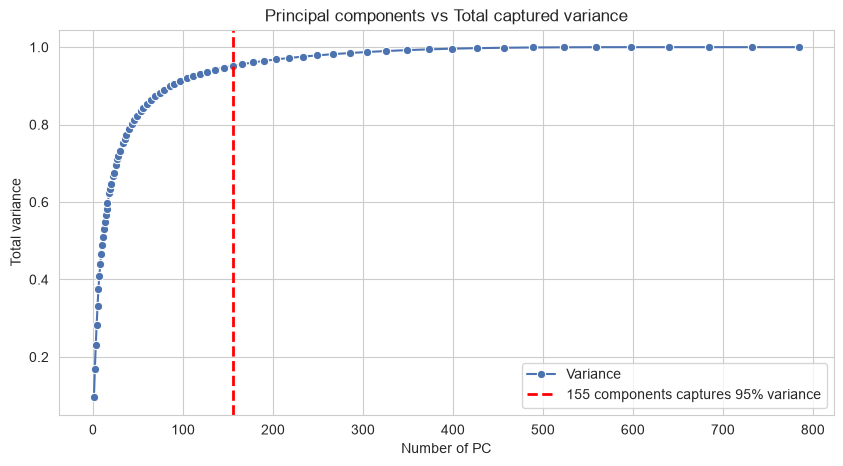

In [14]:
plt.figure(figsize=(10, 5))

var_per = round(var_threshold * 100)
nc_label = f"{var_thr_x} components captures {var_per}% variance"

ax = sns.lineplot(x=ncp_vals, y=tot_vars, marker="o", label="Variance")
ax.axvline(x=var_thr_x, color="red", linestyle="--", linewidth=2, label=nc_label)
plt.title("Principal components vs Total captured variance")
plt.xlabel("Number of PC")
plt.ylabel("Total variance")

plt.legend()
plt.show()

In [15]:
print(f"Number of principal components that are needed to capture {var_per}% of variance: {var_thr_x}")

Number of principal components that are needed to capture 95% of variance: 155
